Step 1: inspect G1 and G2 for collinearity to target: G3

In [4]:
#inspect both math and portugese classes
import pandas as pd, numpy as np

math_class = pd.read_csv('../data/student-mat.csv', sep=';')
math_class.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [5]:
portugese_class = pd.read_csv('../data/student-por.csv', sep=';')
portugese_class.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


## Collinearity check: correlation, condition number, VIF
Multicollinearity means some predictors are (close to) linear combinations of each other. It doesn't hurt prediction much, but it makes regression coefficients unstable and hard to interpret.

- **Correlation matrix**: pairwise linear relationships. |r| > 0.8 between two *predictors* is a warning sign.
- **Condition number**: how close the predictors are to being linearly dependent as a group.
  - On the correlation matrix it is λ_max / λ_min (largest / smallest eigenvalue). Rough guide: > 30 moderate, > 100 serious.
  - On the standardized data matrix X it is the square root of that (what `np.linalg.cond` gives).
- **VIF (variance inflation factor)**: for each predictor, VIF = 1 / (1 − R²) where R² comes from regressing that predictor on all the others. It equals the diagonal of the inverse correlation matrix. VIF = 1 means no collinearity, > 5 moderate, > 10 serious.

The function below does all of this for one dataset, so it can be run on both the math and Portuguese classes.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def collinearity_report(df, target='G3', features=None, high_corr=0.8, name=''):
    """Correlation heatmaps, collinear pairs, condition numbers, and VIF for one dataset."""
    if features is None:   # default: every numeric column except the target
        features = [c for c in df.select_dtypes(include='number').columns if c != target]
    data = df[features + [target]].apply(pd.to_numeric)

    # 1. full correlation matrix heatmap (lower triangle only, upper is a mirror)
    corr = data.corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    size = max(4, 0.6 * len(corr))
    plt.figure(figsize=(size + 2, size))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
    plt.title(f'{name} correlation matrix')
    plt.show()

    # 2. close-up of G1, G2, G3 (skipped if fewer than 2 of them are in the data)
    grades = list(dict.fromkeys(c for c in ['G1', 'G2', target] if c in corr.columns))
    if len(grades) > 1:
        plt.figure(figsize=(4, 3.5))
        sns.heatmap(corr.loc[grades, grades], annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
        plt.title(f'{name}: G1, G2 vs {target}')
        plt.show()

    # 3. pairs of predictors with |r| >= high_corr
    feat_corr = corr.loc[features, features]
    pairs = [(a, b, feat_corr.loc[a, b])
             for i, a in enumerate(features) for b in features[i + 1:]
             if abs(feat_corr.loc[a, b]) >= high_corr]
    pairs = (pd.DataFrame(pairs, columns=['feature_1', 'feature_2', 'r'])
             .sort_values('r', key=abs, ascending=False).reset_index(drop=True))

    # 4. condition numbers
    eigvals = np.linalg.eigvalsh(feat_corr.values)   # sorted smallest to largest
    cond_corr = eigvals[-1] / eigvals[0]
    X = data[features].values
    X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)
    cond_X = np.linalg.cond(X_scaled)

    # 5. VIF = diagonal of the inverse correlation matrix
    vif = pd.Series(np.diag(np.linalg.inv(feat_corr.values)), index=features,
                    name='VIF').sort_values(ascending=False)

    print(f'===== {name} =====')
    print(f'correlation with {target}:')
    print(corr[target].drop(target).sort_values(key=abs, ascending=False).round(3).head(8).to_string())
    print(f'\npredictor pairs with |r| >= {high_corr}:')
    print(pairs.round(3).to_string() if len(pairs) else '  none')
    print(f'\ncondition number of correlation matrix (lambda_max / lambda_min): {cond_corr:.2f}')
    print(f'condition number of standardized X: {cond_X:.2f}')
    print('\nVIF:')
    print(vif.round(2).to_string())

    return {'corr': corr, 'collinear_pairs': pairs, 'eigenvalues': eigvals,
            'condition_number': cond_corr, 'condition_number_scaled_X': cond_X, 'vif': vif}

### All numeric predictors, both classes

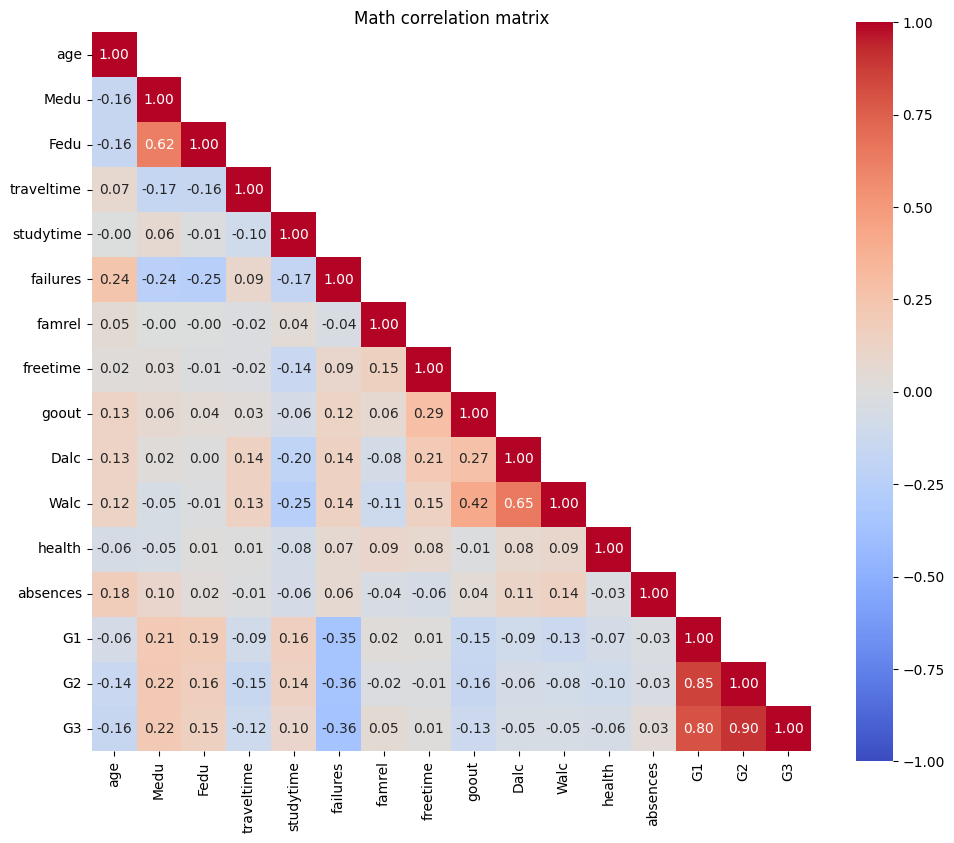

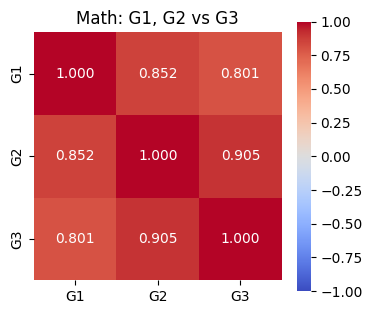

===== Math =====
correlation with G3:
G2            0.905
G1            0.801
failures     -0.360
Medu          0.217
age          -0.162
Fedu          0.152
goout        -0.133
traveltime   -0.117

predictor pairs with |r| >= 0.8:
  feature_1 feature_2      r
0        G1        G2  0.852

condition number of correlation matrix (lambda_max / lambda_min): 20.89
condition number of standardized X: 4.57

VIF:
G2            3.98
G1            3.94
Walc          2.11
Dalc          1.81
Medu          1.77
Fedu          1.72
goout         1.39
failures      1.31
freetime      1.20
age           1.19
studytime     1.15
traveltime    1.09
absences      1.08
famrel        1.08
health        1.06


In [8]:
math_report = collinearity_report(math_class, name='Math')

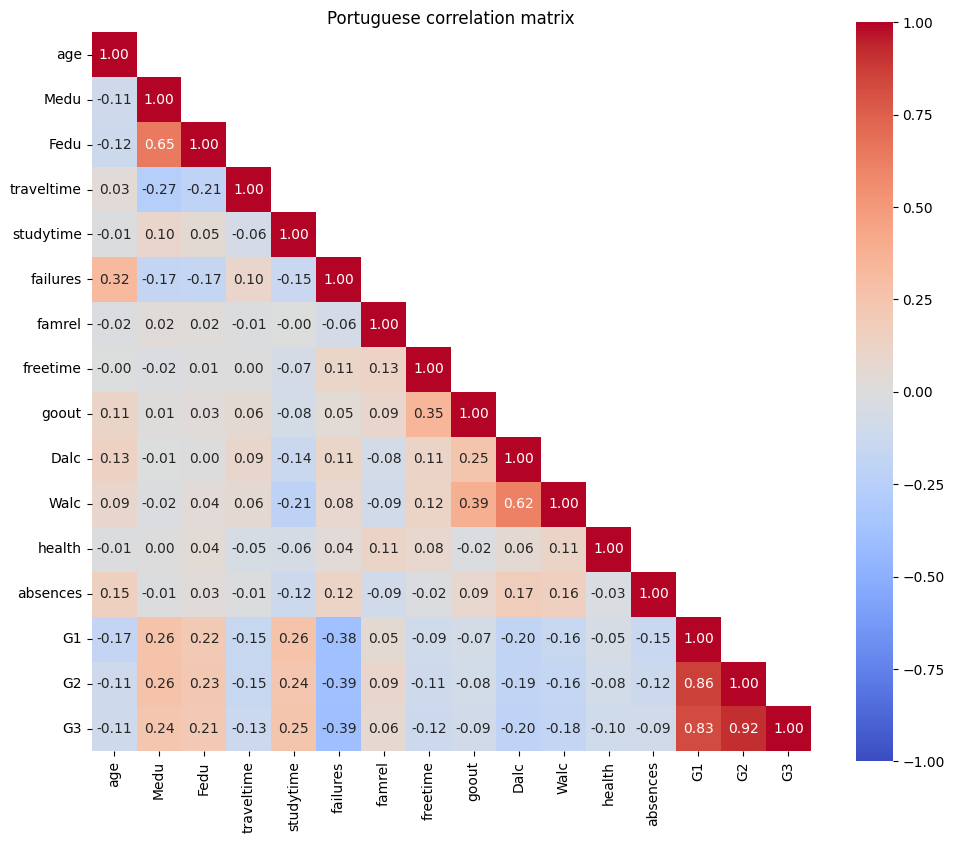

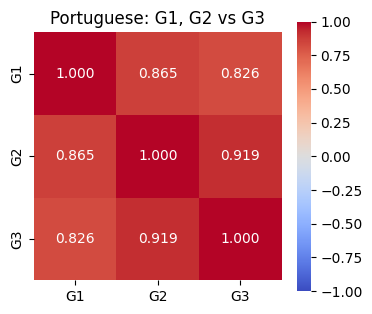

===== Portuguese =====
correlation with G3:
G2           0.919
G1           0.826
failures    -0.393
studytime    0.250
Medu         0.240
Fedu         0.212
Dalc        -0.205
Walc        -0.177

predictor pairs with |r| >= 0.8:
  feature_1 feature_2      r
0        G1        G2  0.865

condition number of correlation matrix (lambda_max / lambda_min): 23.22
condition number of standardized X: 4.82

VIF:
G2            4.21
G1            4.20
Walc          1.90
Medu          1.83
Fedu          1.77
Dalc          1.68
goout         1.37
failures      1.33
age           1.19
freetime      1.19
studytime     1.13
traveltime    1.10
absences      1.09
famrel        1.08
health        1.06


In [9]:
por_report = collinearity_report(portugese_class, name='Portuguese')

### G1 and G2 only
Same function, but only G1 and G2 as predictors, to see how much collinearity there is between just the two earlier grades. With two predictors, VIF = 1 / (1 − r²) where r = corr(G1, G2).

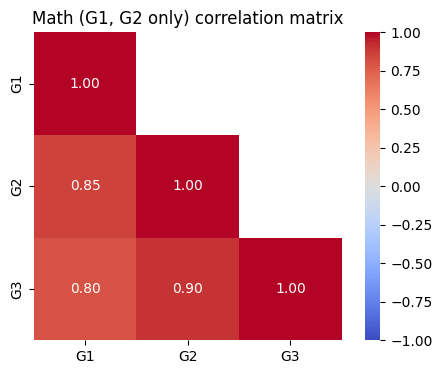

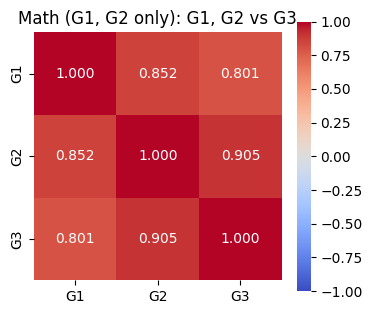

===== Math (G1, G2 only) =====
correlation with G3:
G2    0.905
G1    0.801

predictor pairs with |r| >= 0.8:
  feature_1 feature_2      r
0        G1        G2  0.852

condition number of correlation matrix (lambda_max / lambda_min): 12.52
condition number of standardized X: 3.54

VIF:
G2    3.65
G1    3.65


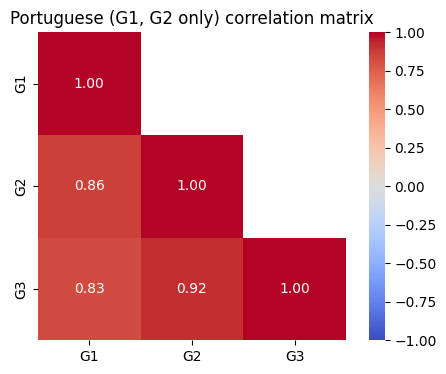

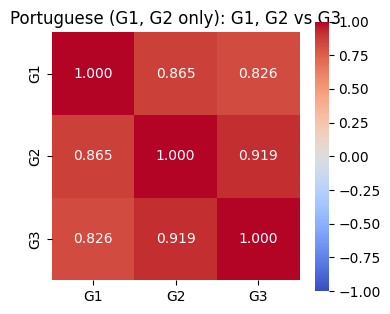

===== Portuguese (G1, G2 only) =====
correlation with G3:
G2    0.919
G1    0.826

predictor pairs with |r| >= 0.8:
  feature_1 feature_2      r
0        G1        G2  0.865

condition number of correlation matrix (lambda_max / lambda_min): 13.81
condition number of standardized X: 3.72

VIF:
G1    3.97
G2    3.97


In [10]:
math_grades_report = collinearity_report(math_class, features=['G1', 'G2'], name='Math (G1, G2 only)')
por_grades_report = collinearity_report(portugese_class, features=['G1', 'G2'], name='Portuguese (G1, G2 only)')

### What the results show
- **G1 and G2 are by far the strongest predictors of G3** in both classes. Math: r(G2, G3) = 0.905, r(G1, G3) = 0.801. Portuguese: r(G2, G3) = 0.919, r(G1, G3) = 0.826. G2 is closer to G3 because it is the more recent grade. The next-best predictor is `failures` at only about −0.36 to −0.39.
- **G1 and G2 are strongly correlated with each other** (0.852 in math, 0.865 in Portuguese). They are the only predictor pair above |r| = 0.8.
- **VIF**: G1 and G2 have VIFs of about 4 in both classes, which is noticeable but below the usual cutoff of 5. Every other predictor is near 1 to 2 (Walc and Dalc are the next highest because they are related to each other). With only G1 and G2 as predictors, VIF = 3.65 (math) and 3.97 (Portuguese), which matches 1 / (1 − r²).
- **Condition number**: about 21 (math) and 23 (Portuguese) for the correlation matrix, and about 4.6 to 4.8 for the standardized X. Both are below the "moderate" threshold of 30, so there is **no severe multicollinearity**.
- **Takeaway**: G1 and G2 carry overlapping information, so in a linear model their individual coefficients will be somewhat unstable (each one "shares credit" with the other). They are not collinear enough to break the model, though. Prediction of G3 should be very good with them included.
- **Math vs Portuguese**: the math class has 38 students with G3 = 0, versus 15 in Portuguese. All 38 math students had a nonzero G1, and 25 of them also had a nonzero G2, so these zeros likely mean the student dropped out or missed the final rather than truly scoring 0. These points pull the math correlations down slightly and are worth looking at before modeling.

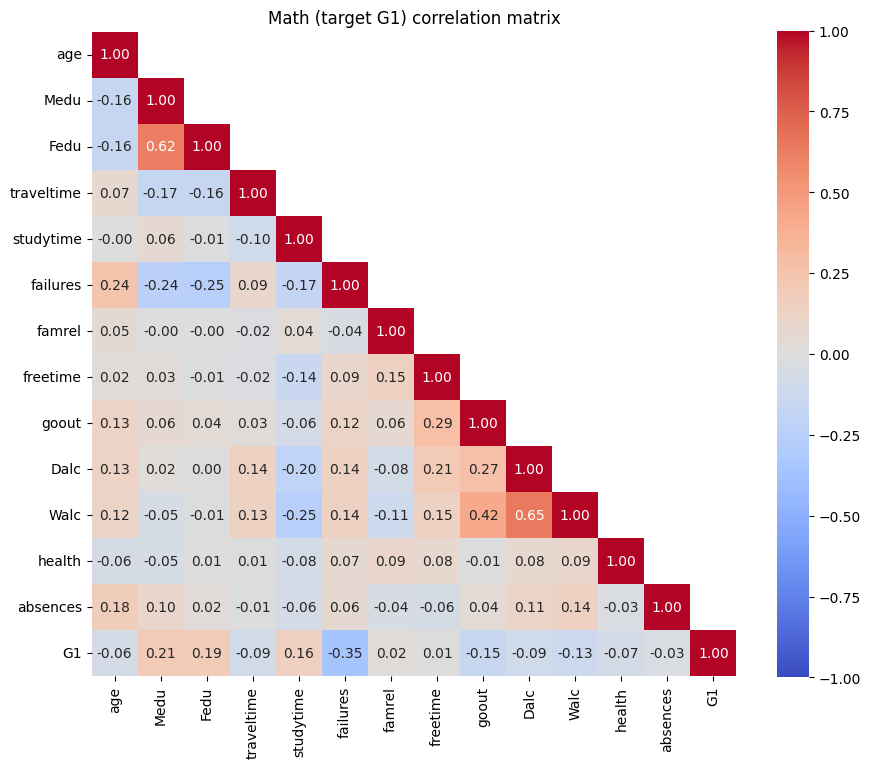

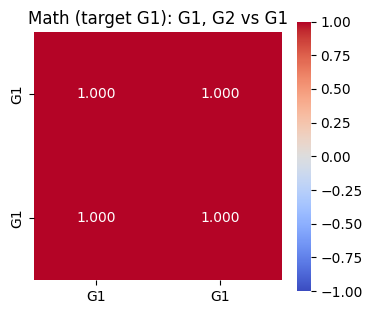

===== Math (target G1) =====
correlation with G1:
failures     -0.355
Medu          0.205
Fedu          0.190
studytime     0.161
goout        -0.149
Walc         -0.126
Dalc         -0.094
traveltime   -0.093

predictor pairs with |r| >= 0.8:
  none

condition number of correlation matrix (lambda_max / lambda_min): 8.04
condition number of standardized X: 2.84

VIF:
Walc          2.09
Dalc          1.81
Medu          1.75
Fedu          1.71
goout         1.35
failures      1.20
freetime      1.18
age           1.16
studytime     1.13
absences      1.08
famrel        1.08
traveltime    1.07
health        1.05


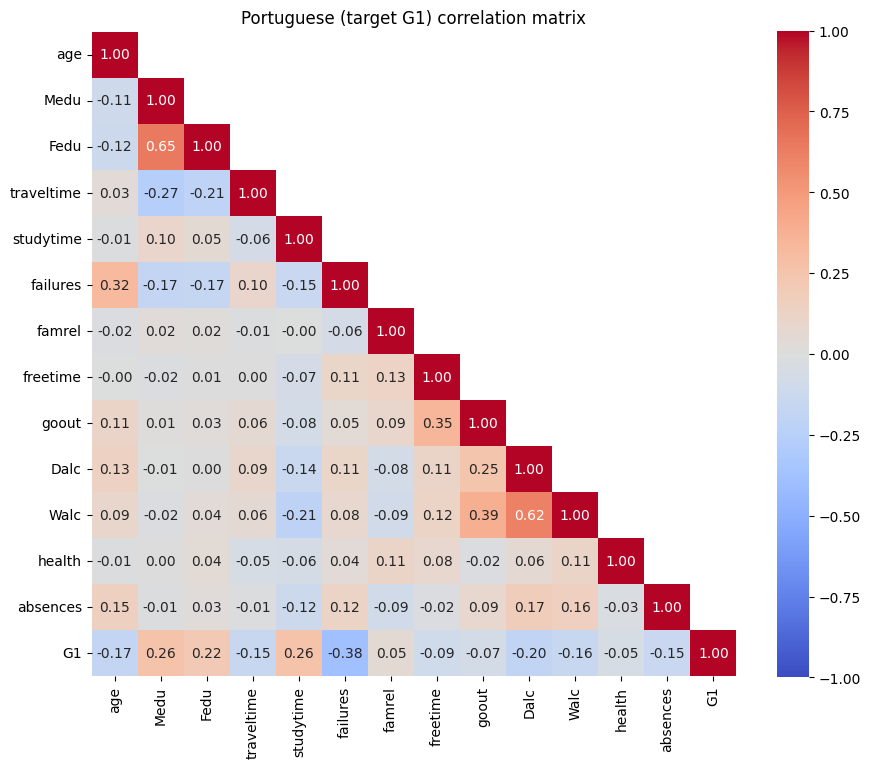

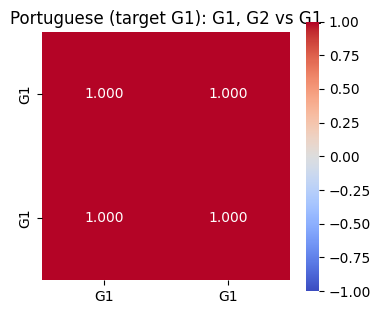

===== Portuguese (target G1) =====
correlation with G1:
failures     -0.384
studytime     0.261
Medu          0.260
Fedu          0.218
Dalc         -0.195
age          -0.174
Walc         -0.156
traveltime   -0.154

predictor pairs with |r| >= 0.8:
  none

condition number of correlation matrix (lambda_max / lambda_min): 7.11
condition number of standardized X: 2.67

VIF:
Walc          1.90
Medu          1.81
Fedu          1.76
Dalc          1.66
goout         1.37
failures      1.20
freetime      1.19
age           1.17
traveltime    1.10
studytime     1.09
absences      1.08
famrel        1.07
health        1.05


In [11]:
math_g1_report = collinearity_report(math_class.drop(columns=['G2', 'G3']), target='G1', name='Math (target G1)')
por_g1_report = collinearity_report(portugese_class.drop(columns=['G2', 'G3']), target='G1', name='Portuguese (target G1)')

### What the results show (target G1)
- **Without the other grades, nothing is strongly related to G1.** The strongest feature is `failures` (past class failures): r = −0.355 in math and −0.384 in Portuguese. Next come parents' education (Medu, Fedu: about 0.19 to 0.26) and `studytime` (0.16 in math, 0.26 in Portuguese). Going out and alcohol use (goout, Walc, Dalc) have small negative correlations.
- **No collinearity problem.** No predictor pair reaches |r| = 0.8, and every VIF is at most about 2.1. The highest is Walc, from its overlap with Dalc, followed by Medu and Fedu, which overlap with each other. The condition number is 8.0 (math) and 7.1 (Portuguese) on the correlation matrix, and about 2.7 to 2.8 on the standardized X, which is well below the warning levels. Removing G2 and G3 took away the only collinear pair (G1 and G2), which is why the condition number dropped from about 21 to about 8.
- **Takeaway**: the features are clean enough for a linear model, but each one explains only a little of G1, so G1 will be much harder to predict than G3 was with G1 and G2 included. The same pattern shows up in both classes, and it is slightly stronger in Portuguese.

## Students who dropped out vs. students who did not drop out
Some students have G3 = 0, and many of those also have G2 = 0. These look like students who **dropped out**, not students who actually scored 0:
- Every student with G2 = 0 also has G3 = 0. They likely left after the first period.
- Other students have G3 = 0 even though G2 > 0. They likely left after the second period.
- **Every student with G3 = 0 has exactly 0 absences**, while the other students average several. Absences were probably just not recorded for students who left. That means `absences` should not be used to predict dropout, or a model would learn a recording artifact.

So the data is split into two problems:
- **Students who dropped out**: classify G3 = 0 (dropped out) vs G3 > 0, using all students.
- **Students who did not drop out**: predict G3 using only students with G3 > 0, so the zeros don't distort the regression.

`split_dropouts` adds a `dropped_out` flag and returns both versions of each dataset.

In [14]:
def split_dropouts(df, name=''):
    """Flag G3 = 0 students as dropouts; return (all students with flag, students who stayed)."""
    df = df.copy()
    df['dropped_out'] = (df['G3'] == 0).astype(int)

    print(f'===== {name} =====')
    print(f"dropouts (G3 = 0): {df['dropped_out'].sum()} of {len(df)} ({df['dropped_out'].mean():.1%})")
    print('\nG2 = 0 vs dropped out:')
    print(pd.crosstab(df['G2'] == 0, df['dropped_out'], rownames=['G2 == 0'], colnames=['dropped_out']))
    print('\nmean absences:')
    print(df.groupby('dropped_out')['absences'].mean().round(2).to_string())
    print()

    stayed = df[df['dropped_out'] == 0].drop(columns='dropped_out')
    return df, stayed

math_all, math_stayed = split_dropouts(math_class, 'Math')
por_all, por_stayed = split_dropouts(portugese_class, 'Portuguese')

===== Math =====
dropouts (G3 = 0): 38 of 395 (9.6%)

G2 = 0 vs dropped out:
dropped_out    0   1
G2 == 0             
False        357  25
True           0  13

mean absences:
dropped_out
0    6.32
1    0.00

===== Portuguese =====
dropouts (G3 = 0): 15 of 649 (2.3%)

G2 = 0 vs dropped out:
dropped_out    0  1
G2 == 0            
False        634  8
True           0  7

mean absences:
dropped_out
0    3.75
1    0.00



In [26]:
for name, stayed, full in [('Math', math_stayed, math_class), ('Portuguese', por_stayed, portugese_class)]:
    assert (stayed['G3'] == 0).sum() == 0, f'{name}: dropouts still present!'
    print(f"{name}: {len(full)} students -> {len(stayed)} who did not drop out, "
          f"{(full['G3'] == 0).sum()} removed, lowest G3 left = {stayed['G3'].min()}")

Math: 395 students -> 357 who did not drop out, 38 removed, lowest G3 left = 4
Portuguese: 649 students -> 634 who did not drop out, 15 removed, lowest G3 left = 1


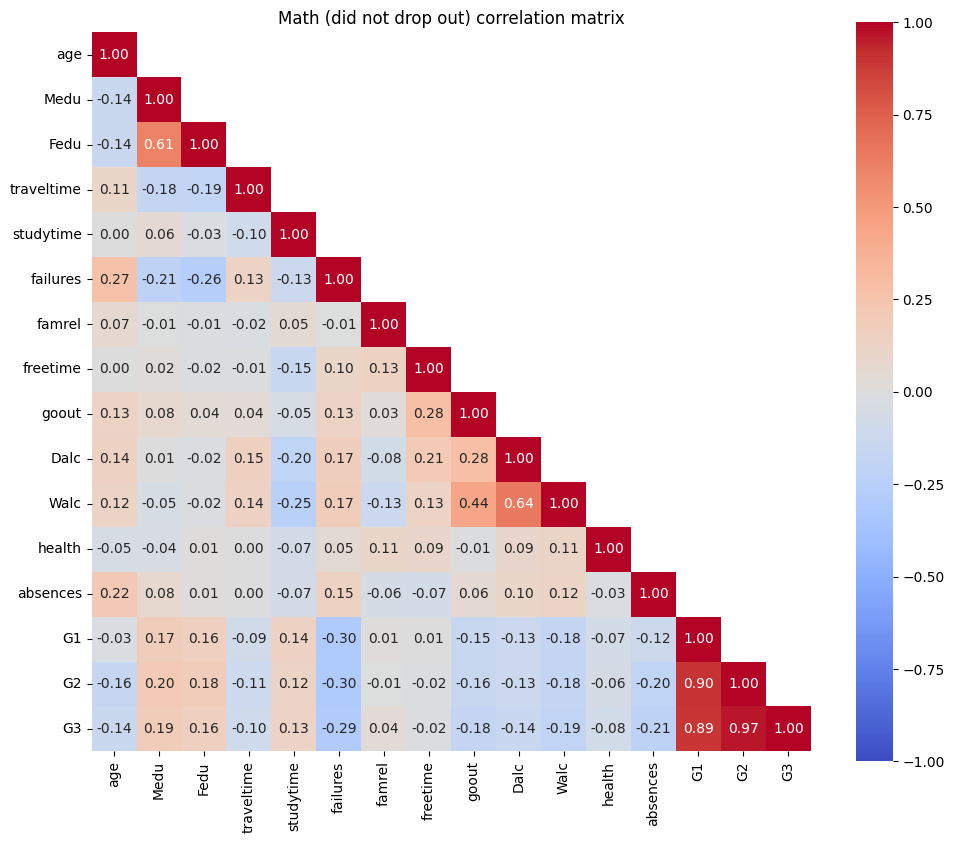

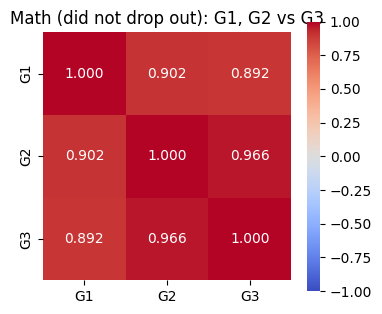

===== Math (did not drop out) =====
correlation with G3:
G2          0.966
G1          0.892
failures   -0.294
absences   -0.213
Medu        0.190
Walc       -0.190
goout      -0.177
Fedu        0.159

predictor pairs with |r| >= 0.8:
  feature_1 feature_2      r
0        G1        G2  0.902

condition number of correlation matrix (lambda_max / lambda_min): 34.50
condition number of standardized X: 5.87

VIF:
G2            6.18
G1            6.09
Walc          2.13
Dalc          1.81
Medu          1.71
Fedu          1.68
goout         1.42
failures      1.29
age           1.27
freetime      1.21
absences      1.15
studytime     1.14
traveltime    1.09
famrel        1.07
health        1.06


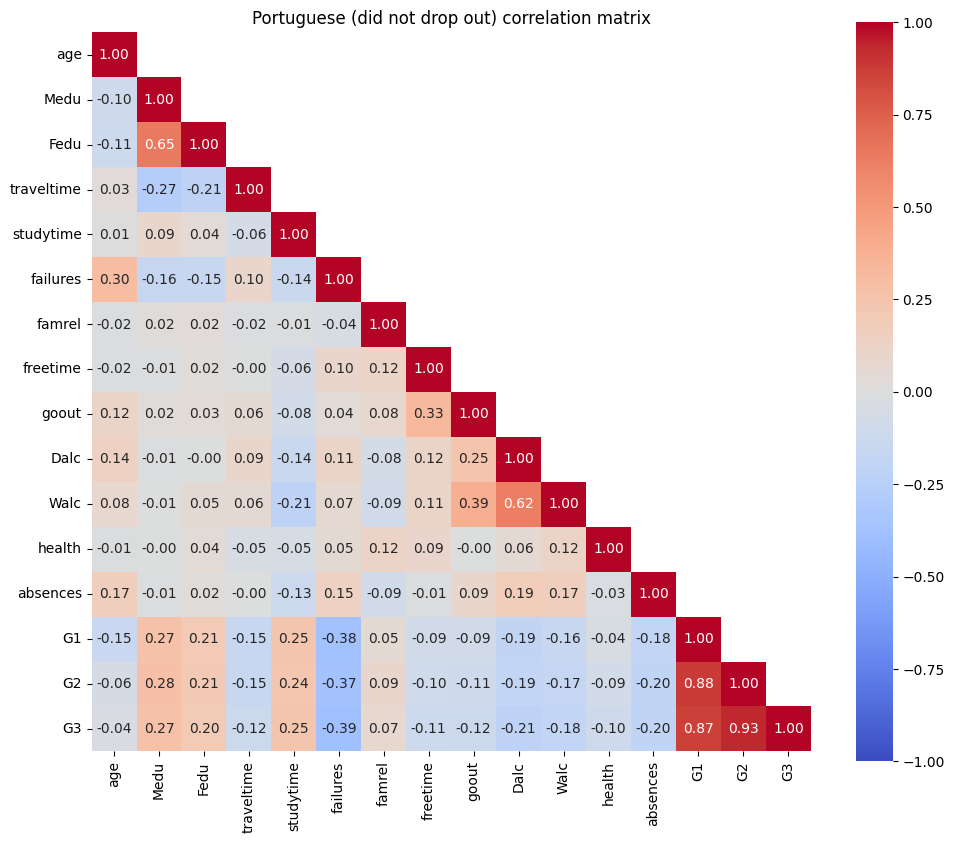

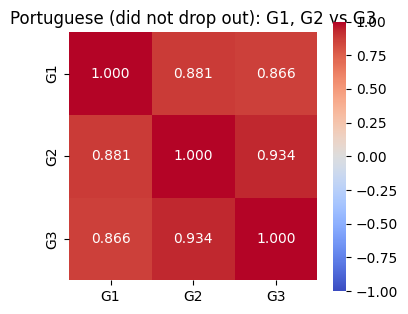

===== Portuguese (did not drop out) =====
correlation with G3:
G2           0.934
G1           0.866
failures    -0.388
Medu         0.272
studytime    0.246
Dalc        -0.211
Fedu         0.197
absences    -0.196

predictor pairs with |r| >= 0.8:
  feature_1 feature_2      r
0        G1        G2  0.881

condition number of correlation matrix (lambda_max / lambda_min): 27.01
condition number of standardized X: 5.20

VIF:
G2            4.88
G1            4.77
Walc          1.91
Medu          1.85
Fedu          1.76
Dalc          1.70
goout         1.36
failures      1.31
age           1.21
freetime      1.18
studytime     1.12
absences      1.12
traveltime    1.10
famrel        1.08
health        1.07


In [19]:
math_stayed_report = collinearity_report(math_stayed, name='Math (did not drop out)')
por_stayed_report = collinearity_report(por_stayed, name='Portuguese (did not drop out)')

### What changes when the dropouts are removed
Dropouts: 38 of 395 in math (9.6%) and 15 of 649 in Portuguese (2.3%). After removing them, 357 math students and 634 Portuguese students remain.

| | Math (all) | Math (did not drop out) | Portuguese (all) | Portuguese (did not drop out) |
|---|---|---|---|---|
| r(G2, G3) | 0.905 | **0.966** | 0.919 | **0.934** |
| r(G1, G3) | 0.801 | **0.892** | 0.826 | **0.866** |
| r(G1, G2) | 0.852 | 0.902 | 0.865 | 0.881 |
| VIF of G1 / G2 | ~3.9 | **~6.1** | ~4.2 | ~4.8 |
| Condition number (corr. matrix) | 20.9 | **34.5** | 23.2 | 27.0 |
| r(absences, G3) | 0.034 | **−0.213** | −0.091 | −0.196 |

- **The grades are even more tied together once the dropouts are gone.** The zeros were the main thing breaking the G1 → G2 → G3 pattern. Among math students who did not drop out, G2 alone explains about 93% of the variance in G3 (0.966² ≈ 0.93).
- **Collinearity is now moderate in math.** The VIFs for G1 and G2 are above 5 and the condition number is above 30. A linear model will have trouble separating the effects of G1 and G2, so its coefficients will be unstable. Tree models like LightGBM aren't affected the same way, because they don't estimate a coefficient for each feature.
- **Absences flipped sign.** In the full math data, absences looked unrelated to G3 (r = 0.034) because the dropouts all had 0 absences and a grade of 0. Among students who did not drop out, more absences means a lower grade (r = −0.213), which is what you'd expect. This confirms that the dropout rows were distorting the data.
- **For students who did not drop out**, any model that includes G2 will be very accurate almost entirely because of G2. The more interesting comparisons are the feature sets without G2 (student background only, or student background + first-period grade), measured against a simple "G3 = G2" baseline.
## Encoding and model evaluation
**Encoding the category columns** (`pd.get_dummies(drop_first=True)`):
- Yes/no columns become a single 0/1 column. For example, `address_U` = 1 for urban and 0 for rural, `Pstatus_T` = 1 if the parents live together, and `higher_yes` = 1 if the student wants higher education.
- Columns with several options (`Mjob`, `Fjob`, `reason`, `guardian`) get one 0/1 column per option, except one. The dropped option is the comparison group. Keeping every option would make the columns always add up to 1, which is perfect collinearity with the intercept.
- Numeric columns that are already ordered (`Medu`, `studytime`, `goout`, ...) stay as they are.

This gives 41 predictor columns (40 for the dropout models, which leave out `absences`). Encoding doesn't learn anything from the data, so it can be done before cross-validation without leakage.

**Evaluating models.** `evaluate_models` runs every model through **repeated cross-validation**: 5 folds, repeated 3 times, so 15 train/test splits. Every model gets exactly the same splits, so the comparison is fair. Standardizing for ridge and logistic regression happens inside a pipeline, so it's refit on each training fold.

**Baselines (no learning).** Each table includes reference "models" that learn nothing. A real model is only useful if it beats them:
- **Average-grade baseline**: predicts every student gets the average G3.
- **Previous-grade baseline (G3 = G1 or G3 = G2)**: predicts the final grade is just the most recent earlier grade.
- **Always "did not drop out" baseline**: predicts that no one drops out. It's right about 90% of the time in math and 98% in Portuguese, which is why accuracy is not used for the dropout models.

**The boosted tree models are kept small** (shallow trees, low learning rate, a minimum number of students per leaf) because the datasets are small and these models overfit easily.

Any model can be added to the comparison:
```python
models = default_models('regression')
models['My model'] = SomeRegressor()
evaluate_models(X, y, models=models, name='...')
```

In [16]:
from sklearn.model_selection import RepeatedKFold, RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.metrics import make_scorer, precision_score, f1_score
from lightgbm import LGBMRegressor, LGBMClassifier
from xgboost import XGBRegressor, XGBClassifier
from catboost import CatBoostRegressor, CatBoostClassifier


def encode(df, target, drop=()):
    """One-hot encode the category columns; return X (every other column) and y."""
    X = pd.get_dummies(df.drop(columns=[target, *drop]), drop_first=True, dtype=int)
    return X, df[target]


class PreviousGradeBaseline(BaseEstimator, RegressorMixin):
    """No-learning reference: predict the final grade as an earlier grade, e.g. G3 = G2."""
    def __init__(self, col='G2'):
        self.col = col

    def fit(self, X, y):
        return self   # nothing to learn

    def predict(self, X):
        return X[self.col].values


def default_models(task, y=None):
    """Fresh, small (regularized) models for task='regression' or 'classification'."""
    if task == 'regression':
        return {
            'Average-grade baseline': DummyRegressor(strategy='mean'),
            'Ridge regression': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
            'Random forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
            'LightGBM': LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=20,
                                      subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                      random_state=42, verbose=-1),
            'XGBoost': XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3,
                                    subsample=0.8, colsample_bytree=0.8, random_state=42),
            'CatBoost': CatBoostRegressor(iterations=500, learning_rate=0.03, depth=4, random_seed=42, verbose=0),
        }
    # classification: every model is told to pay extra attention to the rare dropout class
    pos_weight = (y == 0).sum() / (y == 1).sum() if y is not None else 1.0
    return {
        'Always "did not drop out" baseline': DummyClassifier(strategy='most_frequent'),
        'Logistic regression': make_pipeline(StandardScaler(),
                                             LogisticRegression(class_weight='balanced', max_iter=2000)),
        'Random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced',
                                                random_state=42, n_jobs=-1),
        'LightGBM': LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=10,
                                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                   class_weight='balanced', random_state=42, verbose=-1),
        'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                                 colsample_bytree=0.8, scale_pos_weight=pos_weight, random_state=42),
        'CatBoost': CatBoostClassifier(iterations=500, learning_rate=0.03, depth=4,
                                       auto_class_weights='Balanced', random_seed=42, verbose=0),
    }


def evaluate_models(X, y, task='regression', models=None, name='',
                    n_splits=5, n_repeats=3, seed=42, plot=True):
    """Cross-validate every model on the same folds; return a table of mean and std for each metric."""
    if models is None:
        models = default_models(task, y)

    if task == 'regression':
        cv = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
        scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}
        flip = {'MAE', 'RMSE'}   # sklearn returns these as negatives
        main, ascending = 'MAE', True
    else:
        cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
        scoring = {'ROC-AUC': 'roc_auc', 'PR-AUC': 'average_precision', 'recall': 'recall',
                   'precision': make_scorer(precision_score, zero_division=0),
                   'F1': make_scorer(f1_score, zero_division=0)}
        flip = set()
        main, ascending = 'PR-AUC', False

    rows = []
    for model_name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=scoring)
        row = {'dataset': name, 'model': model_name}
        for metric in scoring:
            vals = scores[f'test_{metric}'] * (-1 if metric in flip else 1)
            row[metric] = vals.mean()
            row[f'{metric}_std'] = vals.std()
        rows.append(row)
    results = pd.DataFrame(rows).sort_values(main, ascending=ascending).reset_index(drop=True)

    if plot:
        plt.figure(figsize=(7, 0.45 * len(results) + 1))
        plt.barh(results['model'], results[main], xerr=results[f'{main}_std'], color='steelblue')
        plt.gca().invert_yaxis()
        plt.xlabel(f"{main} ({'lower' if ascending else 'higher'} is better)")
        plt.title(name)
        plt.tight_layout()
        plt.show()

    print(f'===== {name} =====')
    print(results[['model', *scoring]].round(3).to_string(index=False))
    print()
    return results


# the three feature sets used for both groups of students: name -> grade columns to leave out
feature_sets = {
    'student background only': ('G1', 'G2'),
    'student background + first-period grade (G1)': ('G2',),
    'student background + first- and second-period grades (G1, G2)': (),
}

## Students who did not drop out: predicting the final grade (G3)
Every model is run on three feature sets, from the least to the most information:
- **Student background only**: demographics, family, school, and study and social habits, with no grades. This is what a school knows before the year starts.
- **Student background + first-period grade (G1)**: what the school knows after the first period.
- **Student background + first- and second-period grades (G1, G2)**: what the school knows after the second period.

When G1 or G2 is available, a previous-grade baseline is added (G3 = G1, or G3 = G2) to check whether the models add anything beyond copying the latest grade. The main metric is **MAE**: the average error in grade points on the 0 to 20 scale.

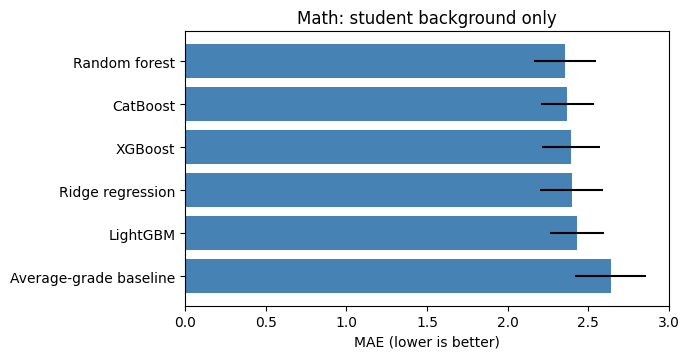

===== Math: student background only =====
                 model   MAE  RMSE     R2
         Random forest 2.356 2.907  0.174
              CatBoost 2.370 2.920  0.164
               XGBoost 2.391 2.931  0.156
      Ridge regression 2.396 2.959  0.141
              LightGBM 2.431 2.993  0.121
Average-grade baseline 2.637 3.221 -0.012



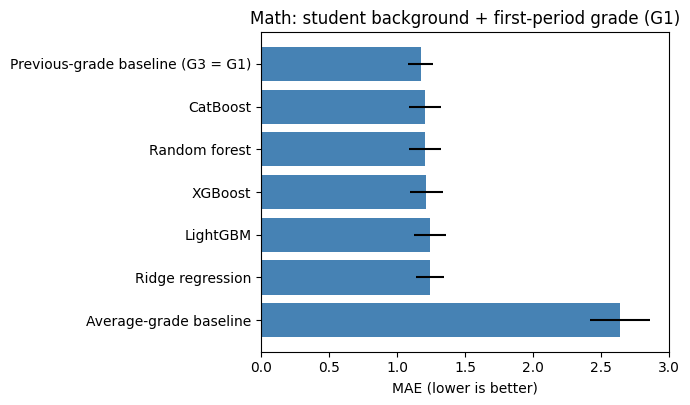

===== Math: student background + first-period grade (G1) =====
                            model   MAE  RMSE     R2
Previous-grade baseline (G3 = G1) 1.174 1.520  0.771
                         CatBoost 1.206 1.469  0.787
                    Random forest 1.206 1.484  0.782
                          XGBoost 1.215 1.495  0.779
                         LightGBM 1.243 1.527  0.769
                 Ridge regression 1.244 1.508  0.775
           Average-grade baseline 2.637 3.221 -0.012



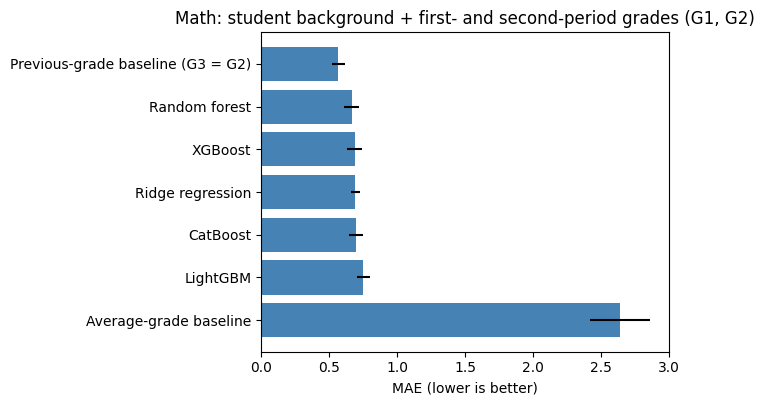

===== Math: student background + first- and second-period grades (G1, G2) =====
                            model   MAE  RMSE     R2
Previous-grade baseline (G3 = G2) 0.569 0.853  0.927
                    Random forest 0.667 0.867  0.925
                          XGBoost 0.689 0.884  0.922
                 Ridge regression 0.695 0.881  0.923
                         CatBoost 0.699 0.897  0.921
                         LightGBM 0.753 0.950  0.911
           Average-grade baseline 2.637 3.221 -0.012



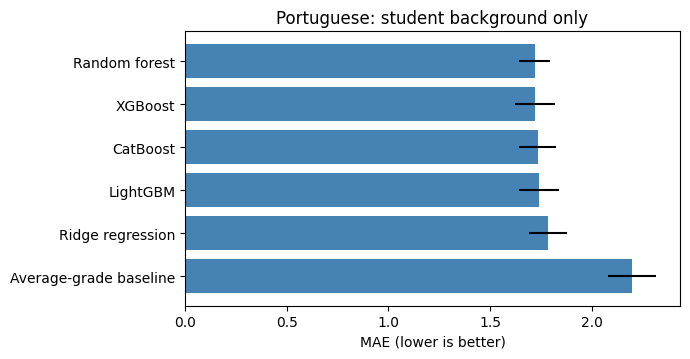

===== Portuguese: student background only =====
                 model   MAE  RMSE     R2
         Random forest 1.719 2.180  0.336
               XGBoost 1.721 2.185  0.333
              CatBoost 1.733 2.195  0.327
              LightGBM 1.740 2.210  0.317
      Ridge regression 1.787 2.257  0.288
Average-grade baseline 2.199 2.690 -0.007



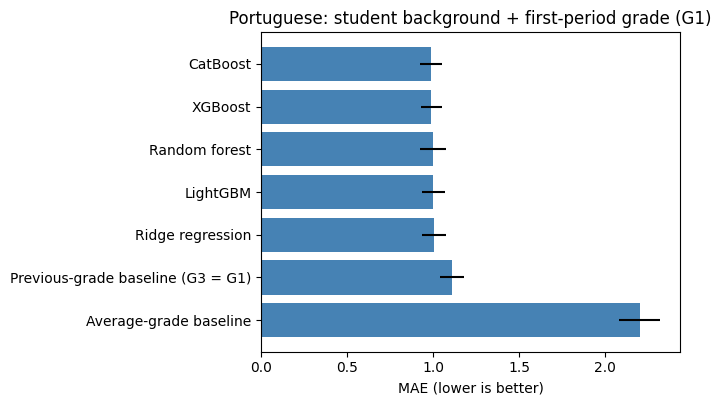

===== Portuguese: student background + first-period grade (G1) =====
                            model   MAE  RMSE     R2
                         CatBoost 0.985 1.275  0.773
                          XGBoost 0.989 1.276  0.772
                    Random forest 0.998 1.294  0.766
                         LightGBM 1.000 1.286  0.769
                 Ridge regression 1.003 1.323  0.755
Previous-grade baseline (G3 = G1) 1.109 1.545  0.665
           Average-grade baseline 2.199 2.690 -0.007



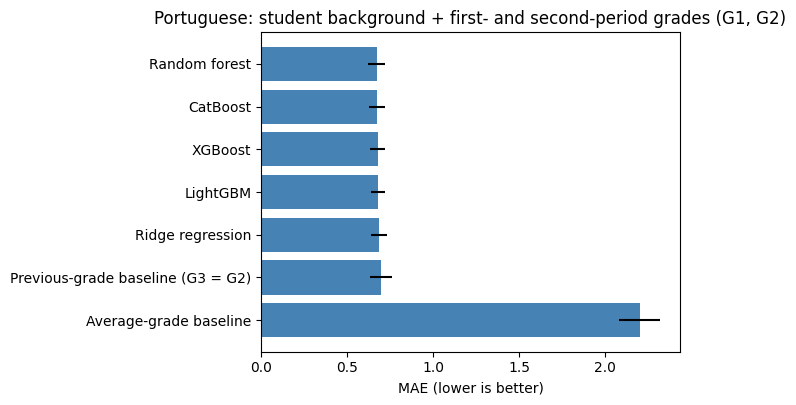

===== Portuguese: student background + first- and second-period grades (G1, G2) =====
                            model   MAE  RMSE     R2
                    Random forest 0.671 0.931  0.876
                         CatBoost 0.673 0.935  0.876
                          XGBoost 0.678 0.943  0.874
                         LightGBM 0.679 0.937  0.875
                 Ridge regression 0.684 0.938  0.876
Previous-grade baseline (G3 = G2) 0.696 1.051  0.844
           Average-grade baseline 2.199 2.690 -0.007



dataset,"Math: student background + first- and second-period grades (G1, G2)",Math: student background + first-period grade (G1),Math: student background only,"Portuguese: student background + first- and second-period grades (G1, G2)",Portuguese: student background + first-period grade (G1),Portuguese: student background only
model,,,,,,
Average-grade baseline,2.637,2.637,2.637,2.199,2.199,2.199
CatBoost,0.699,1.206,2.370,0.673,0.985,1.733
LightGBM,0.753,1.243,2.431,0.679,1.000,1.740
Previous-grade baseline (G3 = G1),NaN,1.174,NaN,NaN,1.109,NaN
Previous-grade baseline (G3 = G2),0.569,NaN,NaN,0.696,NaN,NaN
Random forest,0.667,1.206,2.356,0.671,0.998,1.719
Ridge regression,0.695,1.244,2.396,0.684,1.003,1.787
XGBoost,0.689,1.215,2.391,0.678,0.989,1.721


In [17]:
did_not_drop_out_results = []
for subject, df in [('Math', math_stayed), ('Portuguese', por_stayed)]:
    for label, drop in feature_sets.items():
        X, y = encode(df, 'G3', drop=drop)
        models = default_models('regression')
        if 'G2' in X:
            models['Previous-grade baseline (G3 = G2)'] = PreviousGradeBaseline('G2')
        elif 'G1' in X:
            models['Previous-grade baseline (G3 = G1)'] = PreviousGradeBaseline('G1')
        did_not_drop_out_results.append(evaluate_models(X, y, models=models, name=f'{subject}: {label}'))

# MAE of every model on every dataset / feature set in one table
did_not_drop_out_table = pd.concat(did_not_drop_out_results)
did_not_drop_out_table.pivot(index='model', columns='dataset', values='MAE').round(3)

### What the results show: students who did not drop out
MAE (average error in grade points; lower is better):

| | Math | Portuguese |
|---|---|---|
| Average-grade baseline | 2.64 | 2.20 |
| **Student background only**, best model | 2.36 (random forest), R² = 0.17 | 1.72 (random forest), R² = 0.34 |
| **Student background + G1**, best model | 1.21 (CatBoost / random forest) | 0.99 (CatBoost) |
| Previous-grade baseline (G3 = G1) | **1.17** | 1.11 |
| **Student background + G1, G2**, best model | 0.67 (random forest) | 0.67 (random forest) |
| Previous-grade baseline (G3 = G2) | **0.57** | 0.70 |

- **Student background only**: the models beat the average-grade baseline, but not by much. They explain only about 17% (math) to 34% (Portuguese) of the variance in G3. Background matters, but it leaves most of a student's final grade unexplained.
- **Once a previous grade is known, it does almost all the work.** In **math**, simply copying the previous grade is *better* than every model, by MAE, both with G1 alone (1.17) and with G1 and G2 (0.57). The models add noise on top of a nearly perfect rule, partly because about half of the math students have G3 exactly equal to G2. (By RMSE, which punishes big misses more, the models are slightly better, so they mainly help on the few students whose grade changed a lot.) In **Portuguese**, the models beat the previous-grade baseline slightly (0.99 vs 1.11 with G1, and 0.67 vs 0.70 with G2), so student background adds a little information there.
- **Model comparison**: the tree models (random forest, CatBoost, XGBoost, LightGBM) are all within about 0.05 to 0.1 grade points of each other, and ridge regression is close behind. With this little data, the choice of model matters much less than which features are available. LightGBM was the weakest tree model in math in all three feature sets, possibly because it overfits more easily on a dataset this small.
- **Takeaway**: for students who did not drop out, the final grade is mostly decided by how they were already doing. The most useful prediction is the early one (student background only, or + G1), when a school could still step in.

## Students who dropped out: predicting who drops out
The target is `dropped_out` (1 if G3 = 0), using all students. Two columns are always left out:
- `G3`, because it defines the target.
- `absences`, because every student who dropped out has 0 absences, a recording artifact rather than real behavior.

The same three feature sets are used. Dropouts are rare (9.6% in math, 2.3% in Portuguese), so:
- Every model is weighted to pay extra attention to the dropout class.
- The cross-validation folds are **stratified**, so each fold keeps the same dropout rate.
- The main metric is **PR-AUC** (precision-recall area). It measures how well a model ranks the real dropouts above everyone else. A model that guesses scores about the dropout rate (0.096 in math, 0.023 in Portuguese), and a perfect model scores 1.
- **Recall**: what fraction of the dropouts were caught.
- **Precision**: of the students flagged as dropouts, what fraction actually dropped out.

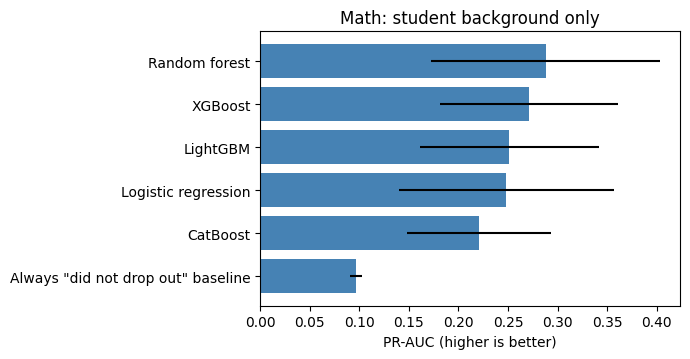

===== Math: student background only =====
                             model  ROC-AUC  PR-AUC  recall  precision    F1
                     Random forest    0.706   0.288   0.089      0.314 0.129
                           XGBoost    0.680   0.271   0.300      0.286 0.287
                          LightGBM    0.687   0.251   0.188      0.237 0.197
               Logistic regression    0.630   0.248   0.435      0.152 0.223
                          CatBoost    0.661   0.221   0.107      0.182 0.129
Always "did not drop out" baseline    0.500   0.096   0.000      0.000 0.000



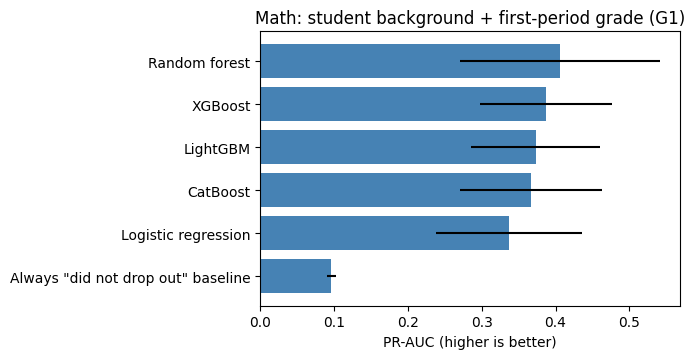

===== Math: student background + first-period grade (G1) =====
                             model  ROC-AUC  PR-AUC  recall  precision    F1
                     Random forest    0.839   0.406   0.292      0.439 0.336
                           XGBoost    0.851   0.387   0.480      0.375 0.415
                          LightGBM    0.848   0.373   0.345      0.335 0.331
                          CatBoost    0.845   0.367   0.294      0.353 0.309
               Logistic regression    0.806   0.337   0.546      0.270 0.356
Always "did not drop out" baseline    0.500   0.096   0.000      0.000 0.000



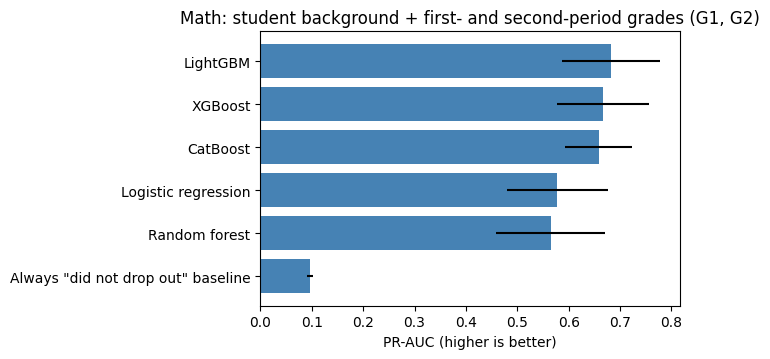

===== Math: student background + first- and second-period grades (G1, G2) =====
                             model  ROC-AUC  PR-AUC  recall  precision    F1
                          LightGBM    0.929   0.682   0.536      0.656 0.572
                           XGBoost    0.924   0.667   0.570      0.566 0.555
                          CatBoost    0.916   0.658   0.544      0.689 0.587
               Logistic regression    0.886   0.578   0.633      0.461 0.517
                     Random forest    0.905   0.565   0.493      0.512 0.483
Always "did not drop out" baseline    0.500   0.096   0.000      0.000 0.000



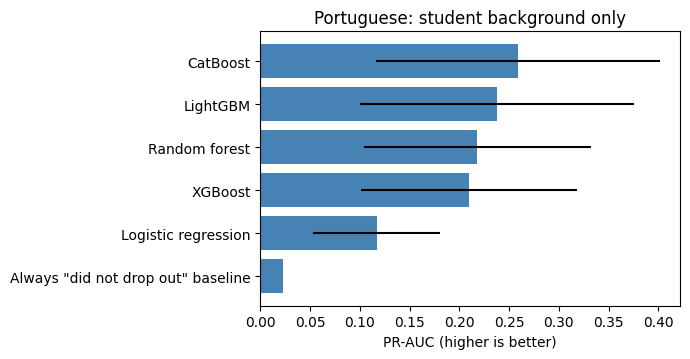

===== Portuguese: student background only =====
                             model  ROC-AUC  PR-AUC  recall  precision    F1
                          CatBoost    0.818   0.259   0.089      0.156 0.109
                          LightGBM    0.835   0.238   0.089      0.178 0.111
                     Random forest    0.861   0.218   0.000      0.000 0.000
                           XGBoost    0.810   0.210   0.111      0.102 0.104
               Logistic regression    0.775   0.117   0.289      0.075 0.117
Always "did not drop out" baseline    0.500   0.023   0.000      0.000 0.000



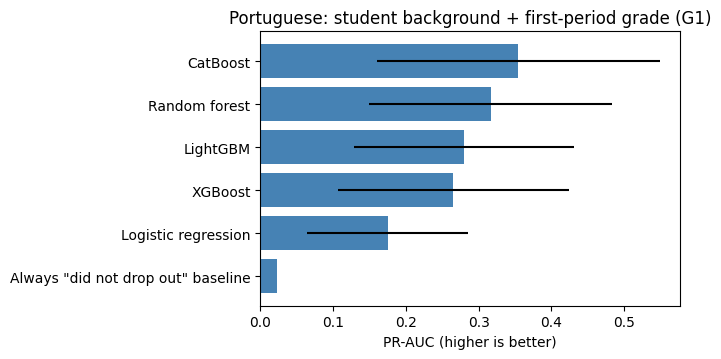

===== Portuguese: student background + first-period grade (G1) =====
                             model  ROC-AUC  PR-AUC  recall  precision    F1
                          CatBoost    0.889   0.355   0.244      0.272 0.234
                     Random forest    0.910   0.316   0.089      0.222 0.122
                          LightGBM    0.842   0.280   0.178      0.184 0.161
                           XGBoost    0.839   0.265   0.289      0.233 0.229
               Logistic regression    0.806   0.175   0.422      0.129 0.192
Always "did not drop out" baseline    0.500   0.023   0.000      0.000 0.000



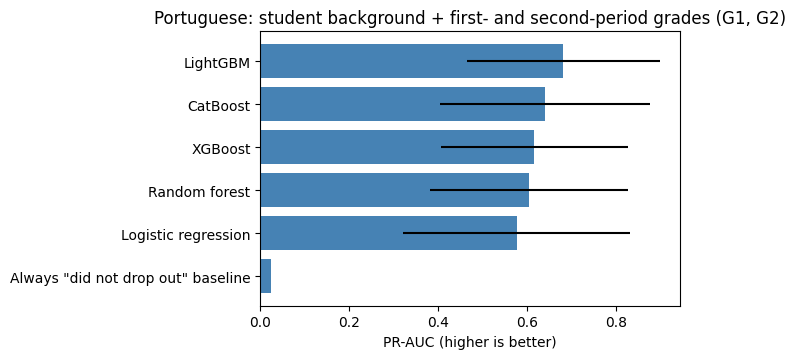

===== Portuguese: student background + first- and second-period grades (G1, G2) =====
                             model  ROC-AUC  PR-AUC  recall  precision    F1
                          LightGBM    0.904   0.682   0.600      0.723 0.617
                          CatBoost    0.960   0.641   0.533      0.480 0.482
                           XGBoost    0.928   0.616   0.556      0.516 0.507
                     Random forest    0.961   0.604   0.333      0.511 0.383
               Logistic regression    0.901   0.576   0.600      0.370 0.429
Always "did not drop out" baseline    0.500   0.023   0.000      0.000 0.000



dataset,"Math: student background + first- and second-period grades (G1, G2)",Math: student background + first-period grade (G1),Math: student background only,"Portuguese: student background + first- and second-period grades (G1, G2)",Portuguese: student background + first-period grade (G1),Portuguese: student background only
model,,,,,,
"Always ""did not drop out"" baseline",0.096,0.096,0.096,0.023,0.023,0.023
CatBoost,0.658,0.367,0.221,0.641,0.355,0.259
LightGBM,0.682,0.373,0.251,0.682,0.280,0.238
Logistic regression,0.578,0.337,0.248,0.576,0.175,0.117
Random forest,0.565,0.406,0.288,0.604,0.316,0.218
XGBoost,0.667,0.387,0.271,0.616,0.265,0.210


In [18]:
dropped_out_results = []
for subject, df in [('Math', math_all), ('Portuguese', por_all)]:
    for label, drop in feature_sets.items():
        X, y = encode(df, 'dropped_out', drop=('G3', 'absences', *drop))
        dropped_out_results.append(evaluate_models(X, y, task='classification', name=f'{subject}: {label}'))

# PR-AUC of every model on every dataset / feature set in one table
dropped_out_table = pd.concat(dropped_out_results)
dropped_out_table.pivot(index='model', columns='dataset', values='PR-AUC').round(3)

### What the results show: students who dropped out
Best PR-AUC per feature set (guessing scores 0.096 in math and 0.023 in Portuguese):

| | Math | Portuguese |
|---|---|---|
| **Student background only** | 0.29 (random forest) | 0.26 (CatBoost) |
| **Student background + G1** | 0.41 (random forest) | 0.36 (CatBoost) |
| **Student background + G1, G2** | **0.68 (LightGBM)** | **0.68 (LightGBM)** |

- **Student background only**: the models do better than guessing (about 3 times the base rate in math), but they can't reliably find dropouts. At best they catch about 30 to 40% of dropouts with low precision. Logistic regression catches the most (about 44% in math), but most of the students it flags didn't actually drop out (precision 0.15).
- **Adding G1 helps a lot.** A low first-period grade is an early warning sign. Every student who dropped out had a G1 between 4 and 12.
- **With G1 and G2, LightGBM is the best model in both subjects.** In math it catches about 54% of dropouts, and about 66% of the students it flags really did drop out. Part of this is easy: 13 of the 38 math dropouts (and 7 of 15 in Portuguese) already have G2 = 0, which gives them away. The harder cases are the students who still had a G2 grade and then left.
- **Portuguese results are unreliable.** There are only 15 dropouts, so each test fold has just 3. One student more or less caught changes recall by about 33 percentage points, which is why the scores jump around between models (for example, random forest has a high ROC-AUC but catches almost no one with student background only).
- **Takeaway**: dropout is hard to predict before any grades exist. The first-period grade is the most useful early signal, and by the second period the boosted models (LightGBM, CatBoost, XGBoost) do a reasonable job.